# Credit Card Fraud Detection: Why 99.8% Accuracy Can Be Useless

**Questions**
1. When fraud is less than 0.2% of transactions, how should a fraud model be evaluated?
2. How much fraud can logistic regression and a random forest catch, and how many false alarms does that cost?
3. How does the choice of decision threshold change the trade-off?

**Data:** 284,807 credit card transactions made by European cardholders over two days in September 2013, of which 492 are fraud. Collected by Worldline and the Machine Learning Group at Université Libre de Bruxelles (Dal Pozzolo et al., 2015).

**Tools:** Python, pandas, matplotlib, scikit-learn.

## 1. Setup and data

The file is about 150 MB, so it is not stored in this repository. The cell below downloads it from [OpenML](https://www.openml.org/d/1597) the first time it runs and caches it in `data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix, accuracy_score)
from pathlib import Path

DEEP, DARK, MID, LIGHT, SOFT, PLUM = "#880E4F", "#D81B60", "#F48FB1", "#F8BBD0", "#E8A0BF", "#AD1457"   # pink palette
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

raw = fetch_openml(data_id=1597, as_frame=True, data_home="data", parser="auto").frame
df = raw.copy()
df["Class"] = df["Class"].astype(int)
print(df.shape)
print("missing values:", int(df.isna().sum().sum()))
print("columns:", ", ".join(df.columns[:4]), "...", ", ".join(df.columns[-3:]))

(284807, 30)
missing values: 0
columns: V1, V2, V3, V4 ... V28, Amount, Class


Each row is one transaction:

- `V1` to `V28`: anonymised features. For confidentiality the bank released principal components instead of the original fields, so they cannot be interpreted directly.
- `Amount`: transaction amount in euros
- The original file also has a `Time` column (seconds since the first transaction). The OpenML copy used here does not include it.
- `Class`: 1 for fraud, 0 for a legitimate transaction

## 2. How rare is fraud?

fraud: 492 of 284,807 transactions (0.173%), or 1 in 579
accuracy of a 'model' that calls everything legitimate: 99.83%



duplicate rows: 9,144

transaction amount (euros):
          count    mean     std  min    50%     90%      99%       max
Class                                                                 
0      284315.0   88.29  250.11  0.0  22.00  202.72  1016.97  25691.16
1         492.0  122.21  256.68  0.0   9.25  346.75  1357.43   2125.87

total value of fraud: €60,128


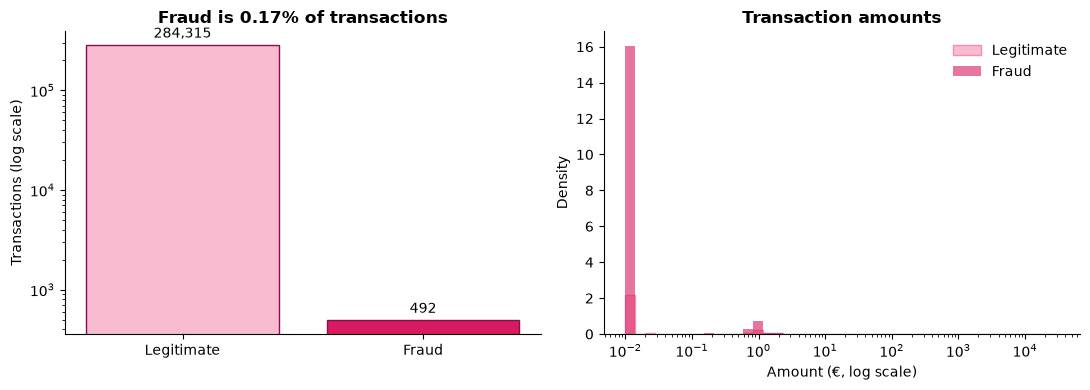

In [2]:
n_fraud, n_all = int(df.Class.sum()), len(df)
print(f"fraud: {n_fraud:,} of {n_all:,} transactions ({n_fraud / n_all:.3%}), or 1 in {n_all / n_fraud:.0f}")
print(f"accuracy of a 'model' that calls everything legitimate: {1 - n_fraud / n_all:.2%}")
print(f"\nduplicate rows: {df.duplicated().sum():,}")
print("\ntransaction amount (euros):")
print(df.groupby("Class").Amount.describe(percentiles=[.5, .9, .99]).round(2).to_string())
print(f"\ntotal value of fraud: €{df.loc[df.Class == 1, 'Amount'].sum():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
b = axes[0].bar(["Legitimate", "Fraud"], [n_all - n_fraud, n_fraud], color=[LIGHT, DARK], edgecolor=DEEP)
axes[0].bar_label(b, labels=[f"{n_all - n_fraud:,}", f"{n_fraud:,}"], padding=3)
axes[0].set_yscale("log"); axes[0].set_ylabel("Transactions (log scale)"); axes[0].set_title("Fraud is 0.17% of transactions")
bins = np.logspace(-2, 4.5, 45)
axes[1].hist(df.loc[df.Class == 0, "Amount"].clip(lower=0.01), bins=bins, color=LIGHT, edgecolor=MID, density=True, label="Legitimate")
axes[1].hist(df.loc[df.Class == 1, "Amount"].clip(lower=0.01), bins=bins, color=DARK, alpha=0.6, density=True, label="Fraud")
axes[1].set_xscale("log"); axes[1].set_xlabel("Amount (€, log scale)"); axes[1].set_ylabel("Density"); axes[1].set_title("Transaction amounts"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("images/class_imbalance.svg"); plt.show()

Fraud is 492 of 284,807 transactions: 0.17%, or about 1 in 579. That has a direct consequence for how models are judged. A "model" that labels every transaction as legitimate is **99.83% accurate** and catches no fraud at all, so accuracy is the wrong measure here. I use:

- **Recall:** of all fraud, what share did the model catch?
- **Precision:** of all the transactions the model flagged, what share were really fraud?
- **PR-AUC:** the area under the precision-recall curve, which summarises both across every threshold. Random guessing scores 0.0017 here, the fraud rate.

Fraud is not simply "large transactions". The median fraud is €9.25, lower than the median legitimate transaction (€22), although fraud has a heavier upper tail. The total value of fraud in the two days is about €60,000.

The data also contains 9,144 exact duplicate rows, which I remove before modelling so the same transaction cannot appear in both the training and the test set.

## 3. Train/test split

I drop exact duplicate rows, then hold out 30% of transactions for testing. The split is stratified so both parts keep the same fraud rate. Everything from here until the final evaluation uses the training set only.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns=["Class"]); y = df.Class
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
print(f"after removing duplicates: {len(df):,} transactions, {int(y.sum())} fraud")
print(f"train: {len(X_train):,} transactions, {int(y_train.sum())} fraud ({y_train.mean():.3%})")
print(f"test:  {len(X_test):,} transactions, {int(y_test.sum())} fraud ({y_test.mean():.3%})")

after removing duplicates: 275,663 transactions, 473 fraud
train: 192,964 transactions, 331 fraud (0.172%)
test:  82,699 transactions, 142 fraud (0.172%)


## 4. Models

Three models:

- **Logistic regression**, with standardised features
- **Logistic regression with class weights**, which makes a missed fraud cost as much as about 580 false alarms during training
- **Random forest** with 200 trees

In [4]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Logistic regression (class-weighted)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
}
proba, rows = {}, []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]; proba[name] = p
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
                 "pr_auc": average_precision_score(y_test, p), "roc_auc": roc_auc_score(y_test, p),
                 "caught": tp, "missed": fn, "false_alarms": fp})
baseline = {"model": "Baseline (always 'legitimate')", "accuracy": 1 - y_test.mean(), "precision": np.nan, "recall": 0.0, "f1": 0.0,
            "pr_auc": y_test.mean(), "roc_auc": 0.5, "caught": 0, "missed": int(y_test.sum()), "false_alarms": 0}
results = pd.DataFrame([baseline] + rows).set_index("model")
print(results.round(4).to_string())

                                      accuracy  precision  recall      f1  pr_auc  roc_auc  caught  missed  false_alarms
model                                                                                                                   
Baseline (always 'legitimate')          0.9983        NaN  0.0000  0.0000  0.0017   0.5000       0     142             0
Logistic regression                     0.9991     0.8681  0.5563  0.6781  0.7210   0.9694      79      63            12
Logistic regression (class-weighted)    0.9773     0.0642  0.9014  0.1198  0.6791   0.9727     128      14          1867
Random forest                           0.9995     0.9224  0.7535  0.8295  0.8193   0.9482     107      35             9


All three models beat the baseline's accuracy slightly, which shows again how little accuracy says. The other columns tell them apart:

- **Logistic regression** is cautious: when it raises an alert it is right 87% of the time, but it catches only 56% of fraud (79 of 142).
- **Class-weighted logistic regression** catches 90% of fraud (128 of 142), but raises 1,867 false alarms to do it. Only 6% of its alerts are real. Its accuracy is the *lowest* of the three even though it catches the most fraud.
- **Random forest** gives the best balance: it catches 75% of fraud (107 of 142) with only 9 false alarms, so 92% of its alerts are real. It also has the highest PR-AUC (0.82).

The ROC-AUC column is a warning in itself. It ranks the random forest last (0.948) and the class-weighted model first (0.973), the opposite of what the precision-recall results show. With so few fraud cases, ROC-AUC is dominated by how the model orders the huge number of legitimate transactions, so PR-AUC is the better guide.

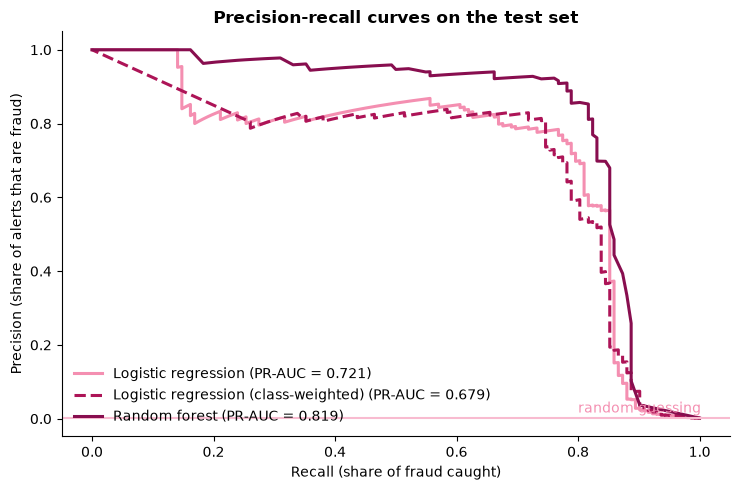

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5))
styles = {"Logistic regression": (MID, "-"), "Logistic regression (class-weighted)": (PLUM, "--"), "Random forest": (DEEP, "-")}
for name, p in proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=styles[name][0], ls=styles[name][1], lw=2.2, label=f"{name} (PR-AUC = {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), color=LIGHT, lw=1.5); ax.text(0.80, y_test.mean() + 0.015, "random guessing", color=MID)
ax.set_xlabel("Recall (share of fraud caught)"); ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Precision-recall curves on the test set"); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig("images/precision_recall_curves.svg"); plt.show()

## 5. Choosing a threshold

A model outputs a probability, and 0.5 is only the default cut-off. Lowering it catches more fraud and raises more false alarms. To choose a threshold without touching the test set, I get out-of-fold predictions for the random forest on the training data (5-fold cross-validation) and look at the trade-off there.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_cv = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
oof = cross_val_predict(rf_cv, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

grid = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
trade = pd.DataFrame([{"threshold": t, "precision": precision_score(y_train, oof >= t), "recall": recall_score(y_train, oof >= t),
                       "f1": f1_score(y_train, oof >= t), "caught": int(((oof >= t) & (y_train == 1)).sum()),
                       "missed": int(((oof < t) & (y_train == 1)).sum()), "false_alarms": int(((oof >= t) & (y_train == 0)).sum())} for t in grid])
print("cross-validated on the training set:")
print(trade.round(3).to_string(index=False))
best_t = trade.loc[trade.f1.idxmax(), "threshold"]
print(f"\nthreshold with the highest F1 in cross-validation: {best_t}")

cross-validated on the training set:
 threshold  precision  recall    f1  caught  missed  false_alarms
      0.05      0.506   0.852 0.635     282      49           275
      0.10      0.709   0.840 0.769     278      53           114
      0.15      0.808   0.840 0.824     278      53            66
      0.20      0.852   0.837 0.845     277      54            48
      0.30      0.898   0.825 0.860     273      58            31
      0.40      0.924   0.813 0.865     269      62            22
      0.50      0.945   0.785 0.858     260      71            15
      0.60      0.961   0.749 0.842     248      83            10
      0.70      0.968   0.722 0.827     239      92             8

threshold with the highest F1 in cross-validation: 0.4


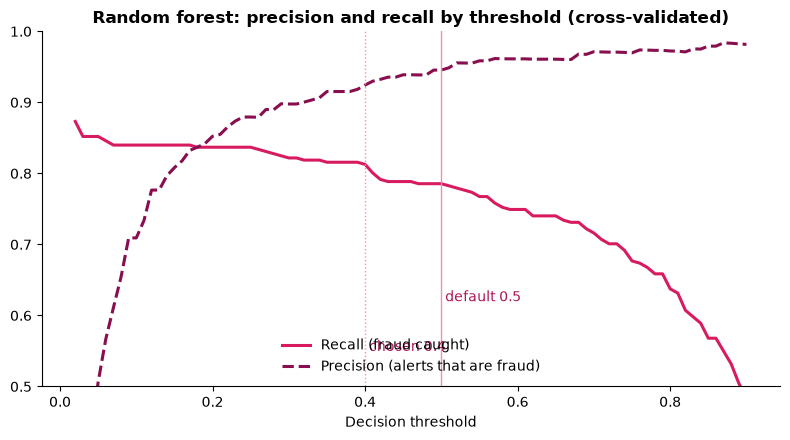

In [7]:
ts = np.linspace(0.02, 0.9, 89)
prec = [precision_score(y_train, oof >= t) for t in ts]; rec = [recall_score(y_train, oof >= t) for t in ts]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ts, rec, color=DARK, lw=2.2, label="Recall (fraud caught)")
ax.plot(ts, prec, color=DEEP, lw=2.2, ls="--", label="Precision (alerts that are fraud)")
ax.axvline(0.5, color=MID, lw=1); ax.text(0.505, 0.62, "default 0.5", color=PLUM)
ax.axvline(best_t, color=MID, lw=1, ls=":"); ax.text(best_t + 0.005, 0.55, f"chosen {best_t}", color=PLUM)
ax.set_xlabel("Decision threshold"); ax.set_ylim(0.5, 1.0); ax.set_title("Random forest: precision and recall by threshold (cross-validated)")
ax.legend(frameon=False, loc="lower center")
plt.tight_layout(); plt.savefig("images/threshold_tradeoff.svg"); plt.show()

The trade-off is uneven. Going from a threshold of 0.7 down to 0.4 buys a lot of recall (72% to 81%) for a small drop in precision (97% to 92%). Below about 0.2, recall barely improves while false alarms multiply: at 0.05 the model catches only 5 more frauds than at 0.2 but raises 275 false alarms instead of 48.

The highest cross-validated F1 score is at **0.4**, slightly below the default, so I use that. In practice the threshold should come from costs: if a missed fraud costs far more than checking a false alarm, a lower threshold such as 0.2 would be justified.

## 6. Final evaluation on the test set

                       precision  recall     f1  caught  missed  false_alarms  fraud_value_caught
random forest                                                                                    
default threshold 0.5      0.922   0.754  0.829     107      35             9               0.703
chosen threshold 0.4       0.888   0.782  0.831     111      31            14               0.772

alerts per 100,000 transactions at the chosen threshold: 151


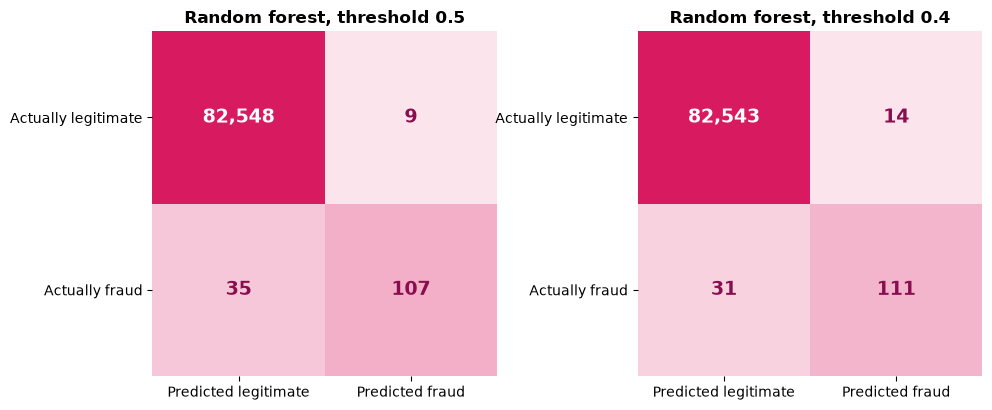

In [8]:
p_rf = proba["Random forest"]
final = []
for label, t in [("default threshold 0.5", 0.5), (f"chosen threshold {best_t}", best_t)]:
    pred = (p_rf >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    amt = X_test.Amount
    final.append({"random forest": label, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                  "f1": f1_score(y_test, pred), "caught": tp, "missed": fn, "false_alarms": fp,
                  "fraud_value_caught": amt[(pred == 1) & (y_test == 1)].sum() / amt[y_test == 1].sum()})
final = pd.DataFrame(final).set_index("random forest")
print(final.round(3).to_string())
print(f"\nalerts per 100,000 transactions at the chosen threshold: {((p_rf >= best_t).sum() / len(y_test) * 100000):.0f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (label, t) in zip(axes, [("Threshold 0.5", 0.5), (f"Threshold {best_t}", best_t)]):
    cm = confusion_matrix(y_test, p_rf >= t)
    ax.imshow(np.log10(cm + 1), cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("pink", ["#FCE4EC", DARK]))
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=14, fontweight="bold", color=DEEP if v < 1000 else "white")
    ax.set_xticks([0, 1], ["Predicted legitimate", "Predicted fraud"]); ax.set_yticks([0, 1], ["Actually legitimate", "Actually fraud"])
    ax.set_title(f"Random forest, {label.lower()}"); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.savefig("images/confusion_matrices.svg"); plt.show()

On the 82,699 test transactions the model never saw, at the chosen threshold of 0.4 the random forest:

- catches **111 of 142 frauds (78%)**, covering 77% of the fraud by value
- raises **14 false alarms**, so 89% of alerts are real
- produces about 151 alerts per 100,000 transactions, a workload a review team could handle

Lowering the threshold from 0.5 to 0.4 caught 4 more frauds at the cost of 5 more false alarms. The improvement is modest because the model is already confident about most of the fraud it can find. The 31 frauds it still misses look like ordinary transactions to this model.

## 7. Which features matter?

V17    0.167
V12    0.133
V14    0.106
V10    0.087
V11    0.069
V16    0.063
V9     0.040
V18    0.033

top 5 features' share of total importance: 56.3% | Amount ranks 22 of 29


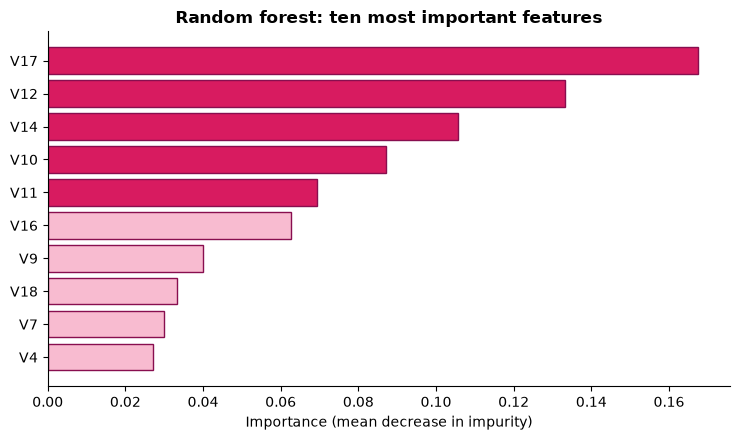

In [9]:
imp = pd.Series(models["Random forest"].feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(8).round(3).to_string())
print(f"\ntop 5 features' share of total importance: {imp.head(5).sum():.1%} | Amount ranks {list(imp.index).index('Amount') + 1} of {len(imp)}")
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(top.index, top.values, color=[DARK if v >= imp.iloc[4] else LIGHT for v in top.values], edgecolor=DEEP)
ax.set_xlabel("Importance (mean decrease in impurity)"); ax.set_title("Random forest: ten most important features")
plt.tight_layout(); plt.savefig("images/feature_importance.svg"); plt.show()

Five features (V17, V12, V14, V10 and V11) account for 56% of the model's total importance. Because the bank released anonymised principal components, there is no way to say what they represent, which is a real limit on this analysis: a fraud team could not turn these results into business rules. The transaction amount ranks 22nd of 29, which matches the earlier finding that fraud is not mainly about large amounts.

## 8. Conclusions

**Findings**

1. **Accuracy is misleading when the outcome is rare.** Calling every transaction legitimate is 99.83% accurate and catches nothing. The class-weighted model caught the most fraud and had the lowest accuracy.
2. **The random forest gave the best balance.** At a threshold of 0.4 it caught 78% of fraud in unseen data with 14 false alarms in 82,699 transactions (precision 89%, PR-AUC 0.82).
3. **There is a real trade-off.** Class-weighted logistic regression caught 90% of fraud but with 1,867 false alarms. Which model is "better" depends on what a missed fraud and a false alarm each cost.
4. **ROC-AUC and PR-AUC disagreed** on which model was best. With 0.17% fraud, PR-AUC is the more honest measure.

**Limitations**

- **Two days of data from 2013.** Fraud patterns change quickly, so this says little about how the model would perform today or even a month later. A real system would be retrained and monitored continuously.
- **Random train/test split.** Transactions were split at random, not by time. In production a model always predicts the future from the past, which is harder, so these results are probably optimistic. The copy of the data used here has no time column, so a time-based split was not possible.
- **Anonymised features.** The inputs are principal components, so the model cannot be explained in business terms.
- **Few fraud cases.** The test set has 142 frauds, so each one moves recall by 0.7 percentage points. The differences between thresholds 0.4 and 0.5 are within that noise.
- **No cost data.** I chose the threshold by F1 score. A bank would choose it from the actual cost of missed fraud against the cost of reviewing alerts and annoying customers.
- **Labels may be incomplete.** Fraud that was never reported is labelled as legitimate.